# Produção hospitalar do SUS em Salvador

**Pergunta:** Como as AIHs processadas se distribuíram por estabelecimento, mês e complexidade entre janeiro e junho de 2024?

Cada linha do SIH/SUS agrupa registros de produção. Somamos `QUANTIDADE` para medir o volume de Autorizações de Internação Hospitalar (AIHs) processadas. No Colab, use **Ambiente de execução → Executar tudo**. A primeira execução baixa o ZIP de 266 MB.

[Fonte oficial](https://dadosabertos.saude.gov.br/dataset/sih_producao_hospitalar) · [Dicionário de dados](https://s3.sa-east-1.amazonaws.com/ckan.saude.gov.br/saes/drac/pdf/SIH_prod_procedimentos_hospitalares_SUS.pdf)

## Base

A primeira célula baixa o ZIP oficial e lê os seis meses. `292740` é o código de Salvador no campo do município onde ocorreu o atendimento. O ZIP anual tem 266 MB, e os seis CSVs usados têm 859.694.413 bytes descompactados. A leitura percorre 2.727.557 linhas no Brasil e guarda 51.775 linhas de Salvador com 16 colunas de origem. O arquivo original contem todos os 12 meses do ano, mas optamos somente pelo primeiro semestre.

In [23]:
import pandas as pd
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

url = "https://s3.sa-east-1.amazonaws.com/ckan.saude.gov.br/saes/drac/SIH_Pprocedimento_Hosp/csv/sih_procedimentos_hospitalares_sus_2024_csv.zip"
if not Path("sih_2024.zip").exists():
    urlretrieve(url, "sih_2024.zip")

partes = []
with ZipFile("sih_2024.zip") as arquivo:
    for mes in ["jan", "fev", "mar", "abr", "mai", "jun"]:
        nome = f"sih_procedimentos_hospitalares_sus_{mes}_2024.csv"
        tabela = pd.read_csv(arquivo.open(nome), sep=";", decimal=",", dtype={"CNES": str, "CNPJ": str})
        partes.append(tabela[tabela["IBGE"] == 292740])

dados = pd.concat(partes, ignore_index=True)
dados.head(6)

,ANO,ANO_MES,UF,IBGE,MUNICIPIO,CNES,CNPJ,NOME_FANTASIA,NATUREZA_JURIDICA,GRUPO_NAT_JUR,IBGE_MUNICIPIO_PACIENTE,FINANCIAMENTO,PROCEDIMENTO,COMPLEXIDADE_PROCEDIMENTO,QUANTIDADE,VALOR
0,2024,202401,BA,292740,SALVADOR,2802104,15178551000117,HOSPITAL SANTO ANTONIO,3999 - ASSOCIACAO PRIVADA,SEM FINS LUCRATIVOS,292910,06 - Média e Alta Complexidade (MAC),0409020176 - URETROTOMIA INTERNA,02 - Média Complexidade,1.0,360.96
1,2024,202401,BA,292740,SALVADOR,2802104,15178551000117,HOSPITAL SANTO ANTONIO,3999 - ASSOCIACAO PRIVADA,SEM FINS LUCRATIVOS,292100,06 - Média e Alta Complexidade (MAC),0409060119 - HISTERECTOMIA C/ ANEXECTOMIA (UNI...,02 - Média Complexidade,1.0,1185.20
2,2024,202401,BA,292740,SALVADOR,2802104,15178551000117,HOSPITAL SANTO ANTONIO,3999 - ASSOCIACAO PRIVADA,SEM FINS LUCRATIVOS,290530,06 - Média e Alta Complexidade (MAC),0413040178 - TRATAMENTO CIRURGICO DE LESOES EX...,02 - Média Complexidade,1.0,782.47
3,2024,202401,BA,292740,SALVADOR,0003840,13937131005704,MATERNIDADE ALBERT SABIN,1023 - ORGAO PUBLICO DO PODER EXECUTIVO ESTADU...,PUBLICO,293320,06 - Média e Alta Complexidade (MAC),0303160047 - TRATAMENTO DE TRANSTORNOS HEMORRA...,02 - Média Complexidade,1.0,278.54
4,2024,202401,BA,292740,SALVADOR,0003840,13937131005704,MATERNIDADE ALBERT SABIN,1023 - ORGAO PUBLICO DO PODER EXECUTIVO ESTADU...,PUBLICO,292740,06 - Média e Alta Complexidade (MAC),0303160020 - TRATAMENTO DE INFECCOES ESPECIFIC...,02 - Média Complexidade,9.0,2629.01
5,2024,202401,BA,292740,SALVADOR,0003859,13937131005372,HOSPITAL GERAL ROBERTO SANTOS,1023 - ORGAO PUBLICO DO PODER EXECUTIVO ESTADU...,PUBLICO,290490,06 - Média e Alta Complexidade (MAC),0305010174 - TRATAMENTO DE INTERCORRÊNCIA EM P...,02 - Média Complexidade,1.0,13845.97


## Conferir e limpar

O CNPJ falta em parte da base. Usamos CNES e mantemos essas linhas. O código `02` aparece com dois rótulos, então agrupamos pelo código.

In [16]:
print("CNPJs em branco:", dados["CNPJ"].isna().sum())
dados["COMPLEXIDADE_PROCEDIMENTO"].value_counts()

CNPJs em branco: 10889


,count
COMPLEXIDADE_PROCEDIMENTO,
02 - M dia Complexidade,34552
03 - Alta Complexidade,10663
02 - Média Complexidade,6560


In [17]:
dados["complexidade"] = dados["COMPLEXIDADE_PROCEDIMENTO"].str[:2].map({
    "02": "Média complexidade", "03": "Alta complexidade"
})
dados["complexidade"].value_counts()

,count
complexidade,
Média complexidade,41112
Alta complexidade,10663


## Hospitais que tiveram mais AIHs

In [18]:
por_hospital = dados.groupby(["CNES", "NOME_FANTASIA"])["QUANTIDADE"].sum()
por_hospital.sort_values(ascending=False).head()

,,QUANTIDADE
CNES,NOME_FANTASIA,
2802104,HOSPITAL SANTO ANTONIO,11933.0
0003859,HOSPITAL GERAL ROBERTO SANTOS,11028.0
0004294,HOSPITAL GERAL DO ESTADO,8396.0
6595197,HOSPITAL DO SUBURBIO,8051.0
3956369,MATERNIDADE PROFESSOR JOSE MARIA DE MAGALHAES NETO,7322.0


## Mês que teve o maior volume

In [19]:
por_mes = dados.groupby("ANO_MES")["QUANTIDADE"].sum()
por_mes

,QUANTIDADE
ANO_MES,
202401,19616.0
202402,19771.0
202403,21417.0
202404,21718.0
202405,20995.0
202406,19753.0


<Axes: title={'center': 'AIHs por mês de processamento'}, xlabel='ANO_MES', ylabel='AIHs'>

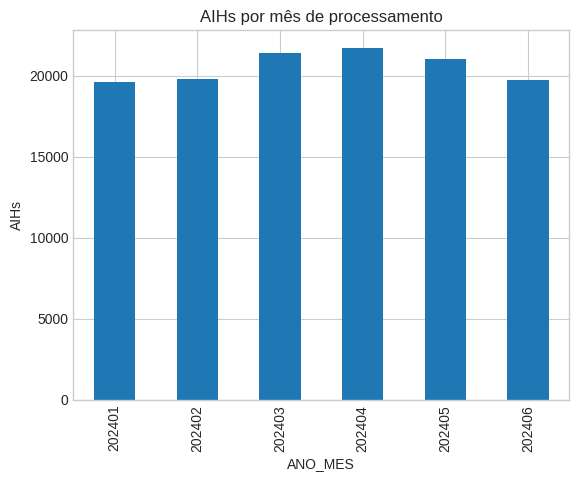

In [20]:
por_mes.plot.bar(title="AIHs por mês de processamento", ylabel="AIHs")

## Nível de complexidade

In [21]:
por_complexidade = dados.groupby("complexidade")["QUANTIDADE"].sum()
percentual = 100 * por_complexidade / por_complexidade.sum()
percentual.round(1)

,QUANTIDADE
complexidade,
Alta complexidade,14.7
Média complexidade,85.3


**O que apareceu:** Hospital Santo Antônio liderou com 11.933 AIHs. Abril teve o maior volume, com 21.718. Média complexidade representou 85,3% do semestre.

Usamos as quantidades originais para comparar volumes. O mês é o de processamento e as tabelas descrevem a produção registrada.

In [22]:
dados.to_parquet("salvador_2024s1.parquet", index=False)